In [1]:
from pathlib import Path
import os
import sys

from google.colab import drive

# Mount Google Drive
drive.mount("/content/drive")

# Persistent project location
PROJECT_ROOT = Path("/content/drive/MyDrive/LipScribe")

# Expected project folders
PROJECT_DIRS = [
    "notebooks",
    "src",
    "src/lipscribe",
    "tests",
    "scripts",
    "data/clips",
    "data/GRID",
    "data/MUSAN",
    "artifacts/contact_sheets",
    "artifacts/crops",
    "artifacts/logs",
    "artifacts/results",
    "checkpoints",
    "configs",
]

# Create any missing folders
for directory in PROJECT_DIRS:
    (PROJECT_ROOT / directory).mkdir(parents=True, exist_ok=True)

# Use the project root as the working directory
os.chdir(PROJECT_ROOT)

# Make src importable
SRC_PATH = str(PROJECT_ROOT / "src")
if SRC_PATH not in sys.path:
    sys.path.insert(0, SRC_PATH)

print("Google Drive mounted successfully.")
print("Project root:", PROJECT_ROOT)
print("Working directory:", Path.cwd())
print("Project root exists:", PROJECT_ROOT.exists())


Mounted at /content/drive
Google Drive mounted successfully.
Project root: /content/drive/MyDrive/LipScribe
Working directory: /content/drive/MyDrive/LipScribe
Project root exists: True


In [2]:
import sys
import platform
from pathlib import Path

print("Python:", sys.version)
print("Platform:", platform.platform())
print("\nProject folders:")

for path in sorted(PROJECT_ROOT.rglob("*")):
    if path.is_dir():
        relative_path = path.relative_to(PROJECT_ROOT)
        print(f"  {relative_path}/")

print("\nCurrent working directory:", Path.cwd())
print("Source path in sys.path:", SRC_PATH in sys.path)


Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
Platform: Linux-6.6.122+-x86_64-with-glibc2.39

Project folders:
  .pytest_cache/
  .pytest_cache/v/
  .pytest_cache/v/cache/
  artifacts/
  artifacts/contact_sheets/
  artifacts/crops/
  artifacts/logs/
  artifacts/results/
  checkpoints/
  configs/
  data/
  data/GRID/
  data/MUSAN/
  data/clips/
  models/
  notebooks/
  scripts/
  src/
  src/lipscribe/
  src/lipscribe/__pycache__/
  tests/
  tests/__pycache__/

Current working directory: /content/drive/MyDrive/LipScribe
Source path in sys.path: True


In [3]:
!pip install -q mediapipe==0.10.35 opencv-python-headless pytest


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 119.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.7/137.7 kB 15.1 MB/s eta 0:00:00


In [4]:
import sys
import cv2
import mediapipe as mp
import numpy as np

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("OpenCV:", cv2.__version__)
print("MediaPipe:", mp.__version__)
print("Has mp.solutions:", hasattr(mp, "solutions"))
print("Has mp.tasks:", hasattr(mp, "tasks"))
print("MediaPipe public attributes:")
print([name for name in dir(mp) if not name.startswith("_")])


Python: 3.13.15
NumPy: 2.1.3
OpenCV: 4.14.0
MediaPipe: 0.10.35
Has mp.solutions: False
Has mp.tasks: True
MediaPipe public attributes:
['Image', 'ImageFormat', 'tasks']


In [5]:
import mediapipe as mp
import inspect

print("MediaPipe version:", mp.__version__)

print("\nMediaPipe task namespaces:")
print(dir(mp.tasks))

print("\nVision namespace:")
print(dir(mp.tasks.vision))


MediaPipe version: 0.10.35

MediaPipe task namespaces:
['BaseOptions', '__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__path__', '__spec__', 'audio', 'components', 'genai', 'text', 'vision']

Vision namespace:
['FaceDetector', 'FaceDetectorOptions', 'FaceDetectorResult', 'FaceLandmarker', 'FaceLandmarkerOptions', 'FaceLandmarkerResult', 'FaceLandmarksConnections', 'GestureRecognizer', 'GestureRecognizerOptions', 'GestureRecognizerResult', 'HandLandmarker', 'HandLandmarkerOptions', 'HandLandmarkerResult', 'HandLandmarksConnections', 'HolisticLandmarker', 'HolisticLandmarkerOptions', 'HolisticLandmarkerResult', 'ImageClassifier', 'ImageClassifierOptions', 'ImageClassifierResult', 'ImageEmbedder', 'ImageEmbedderOptions', 'ImageEmbedderResult', 'ImageProcessingOptions', 'ImageSegmenter', 'ImageSegmenterOptions', 'InteractiveSegmenter', 'InteractiveSegmenterOptions', 'InteractiveSegmenterRegionOfInterest', 'ObjectDetector', 'ObjectDetectorOpti

In [6]:
from mediapipe.tasks.python import vision

names = [
    name for name in dir(vision)
    if "Face" in name or "Landmark" in name or "Running" in name
]

print("Relevant vision classes:")
for name in names:
    print("-", name)


Relevant vision classes:
- FaceDetector
- FaceDetectorOptions
- FaceDetectorResult
- FaceLandmarker
- FaceLandmarkerOptions
- FaceLandmarkerResult
- FaceLandmarksConnections
- HandLandmarker
- HandLandmarkerOptions
- HandLandmarkerResult
- HandLandmarksConnections
- HolisticLandmarker
- HolisticLandmarkerOptions
- HolisticLandmarkerResult
- PoseLandmark
- PoseLandmarker
- PoseLandmarkerOptions
- PoseLandmarkerResult
- PoseLandmarksConnections
- RunningMode


In [7]:
from mediapipe.tasks.python import vision

connections = vision.FaceLandmarksConnections

print("Type:", type(connections))
print("Available attributes:")
print([name for name in dir(connections) if not name.startswith("_")])


Type: <class 'type'>
Available attributes:
['Connection', 'FACE_LANDMARKS_CONTOURS', 'FACE_LANDMARKS_FACE_OVAL', 'FACE_LANDMARKS_LEFT_EYE', 'FACE_LANDMARKS_LEFT_EYEBROW', 'FACE_LANDMARKS_LEFT_IRIS', 'FACE_LANDMARKS_LIPS', 'FACE_LANDMARKS_NOSE', 'FACE_LANDMARKS_RIGHT_EYE', 'FACE_LANDMARKS_RIGHT_EYEBROW', 'FACE_LANDMARKS_RIGHT_IRIS', 'FACE_LANDMARKS_TESSELATION']


In [8]:
# Inspect the object representation and any likely facial connection groups
print(connections)


<class 'mediapipe.tasks.python.vision.face_landmarker.FaceLandmarksConnections'>


In [9]:
from mediapipe.tasks.python import vision

lip_connections = vision.FaceLandmarksConnections.FACE_LANDMARKS_LIPS

print("Connection object type:", type(lip_connections))
print("Number of lip connections:", len(lip_connections))

# Extract the landmark indices from the official MediaPipe connections
lip_indices = sorted({
    index
    for connection in lip_connections
    for index in (connection.start, connection.end)
})

print("Number of unique lip indices:", len(lip_indices))
print("Lip indices:", lip_indices)


Connection object type: <class 'list'>
Number of lip connections: 40
Number of unique lip indices: 40
Lip indices: [0, 13, 14, 17, 37, 39, 40, 61, 78, 80, 81, 82, 84, 87, 88, 91, 95, 146, 178, 181, 185, 191, 267, 269, 270, 291, 308, 310, 311, 312, 314, 317, 318, 321, 324, 375, 402, 405, 409, 415]


In [10]:
from pathlib import Path
import urllib.request

MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

FACE_LANDMARKER_MODEL = MODEL_DIR / "face_landmarker.task"

MODEL_URL = (
    "https://storage.googleapis.com/mediapipe-models/"
    "face_landmarker/face_landmarker/float16/1/face_landmarker.task"
)

if FACE_LANDMARKER_MODEL.exists():
    print("Model already exists. Skipping download.")
else:
    print("Downloading Face Landmarker model...")
    urllib.request.urlretrieve(MODEL_URL, FACE_LANDMARKER_MODEL)
    print("Download complete.")

print("Model path:", FACE_LANDMARKER_MODEL)
print(
    "Model size:",
    round(FACE_LANDMARKER_MODEL.stat().st_size / (1024 * 1024), 2),
    "MB",
)


Model already exists. Skipping download.
Model path: /content/drive/MyDrive/LipScribe/models/face_landmarker.task
Model size: 3.58 MB


In [11]:
assert FACE_LANDMARKER_MODEL.exists()
assert FACE_LANDMARKER_MODEL.stat().st_size > 1_000_000

print("Face Landmarker model verified successfully.")


Face Landmarker model verified successfully.


In [12]:
from pathlib import Path

CLIPS_DIR = PROJECT_ROOT / "data" / "clips"

video_extensions = {".mp4", ".avi", ".mov", ".mkv", ".webm"}

clips = sorted(
    path for path in CLIPS_DIR.iterdir()
    if path.is_file() and path.suffix.lower() in video_extensions
)

print("Clips folder:", CLIPS_DIR)
print("Number of video clips:", len(clips))

for index, clip in enumerate(clips, start=1):
    size_mb = clip.stat().st_size / (1024 * 1024)
    print(f"{index}. {clip.name} ({size_mb:.2f} MB)")

if len(clips) < 5:
    print("\nPlease add at least five video clips to:")
    print(CLIPS_DIR)
else:
    print("\nAt least five clips are available.")


Clips folder: /content/drive/MyDrive/LipScribe/data/clips
Number of video clips: 5
1. clip_1.mp4 (0.76 MB)
2. clip_2.mp4 (0.39 MB)
3. clip_3.mp4 (0.51 MB)
4. clip_4.mp4 (0.55 MB)
5. clip_5.mp4 (0.29 MB)

At least five clips are available.


In [13]:
import cv2
import mediapipe as mp

from mediapipe.tasks import python
from mediapipe.tasks.python import vision

# Select the first clip
test_clip = clips[0]

# Configure MediaPipe Face Landmarker for video input
base_options = python.BaseOptions(
    model_asset_path=str(FACE_LANDMARKER_MODEL)
)

options = vision.FaceLandmarkerOptions(
    base_options=base_options,
    running_mode=vision.RunningMode.VIDEO,
    num_faces=1,
    output_face_blendshapes=False,
    output_facial_transformation_matrixes=False,
    min_face_detection_confidence=0.5,
    min_face_presence_confidence=0.5,
    min_tracking_confidence=0.5,
)

cap = cv2.VideoCapture(str(test_clip))

assert cap.isOpened(), f"Could not open video: {test_clip}"

fps = cap.get(cv2.CAP_PROP_FPS)
frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

print("Clip:", test_clip.name)
print("FPS:", fps)
print("Frame count:", frame_count)
print("Resolution:", width, "x", height)

detected_frames = 0
checked_frames = 0

with vision.FaceLandmarker.create_from_options(options) as landmarker:
    while checked_frames < min(frame_count, 10):
        ok, frame_bgr = cap.read()

        if not ok:
            break

        # OpenCV reads BGR; MediaPipe expects SRGB
        frame_rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)

        mp_image = mp.Image(
            image_format=mp.ImageFormat.SRGB,
            data=frame_rgb,
        )

        # VIDEO mode requires timestamps in milliseconds.
        timestamp_ms = int(round(checked_frames * 1000 / fps))

        result = landmarker.detect_for_video(mp_image, timestamp_ms)

        if result.face_landmarks:
            detected_frames += 1

        checked_frames += 1

cap.release()

print("Frames checked:", checked_frames)
print("Frames with detected face:", detected_frames)


Clip: clip_1.mp4
FPS: 30.0
Frame count: 107
Resolution: 1080 x 608
Frames checked: 10
Frames with detected face: 10


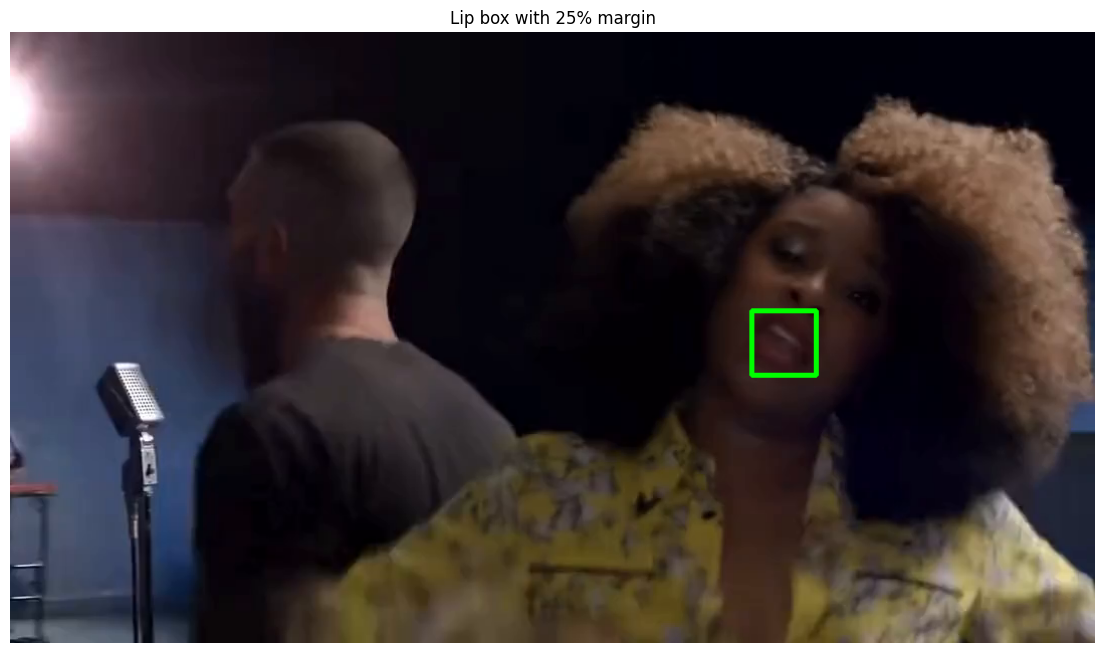

Frame size: 1080 x 608
Lip box: (738, 277, 802, 341)
Square side: 63.95


In [14]:
import cv2
import mediapipe as mp
import numpy as np
import matplotlib.pyplot as plt

from mediapipe.tasks import python
from mediapipe.tasks.python import vision

# Read the first frame from clip_1
cap = cv2.VideoCapture(str(clips[0]))
ok, frame_bgr = cap.read()
cap.release()

assert ok, "Could not read the first frame."

frame_rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
height, width = frame_rgb.shape[:2]

# Reuse the Face Landmarker configuration
with vision.FaceLandmarker.create_from_options(options) as landmarker:
    mp_image = mp.Image(
        image_format=mp.ImageFormat.SRGB,
        data=frame_rgb,
    )
    result = landmarker.detect_for_video(mp_image, timestamp_ms=0)

assert result.face_landmarks, "No face detected in the first frame."

# Get the first detected face
face_landmarks = result.face_landmarks[0]

# Convert official lip landmarks from normalized coordinates to pixels
lip_points = np.array(
    [
        [
            face_landmarks[index].x * width,
            face_landmarks[index].y * height,
        ]
        for index in lip_indices
    ],
    dtype=np.float32,
)

x_min, y_min = lip_points.min(axis=0)
x_max, y_max = lip_points.max(axis=0)

# Square box with 25% margin
lip_width = x_max - x_min
lip_height = y_max - y_min
side = max(lip_width, lip_height) * 1.25

center_x = (x_min + x_max) / 2
center_y = (y_min + y_max) / 2

box_x0 = int(round(center_x - side / 2))
box_y0 = int(round(center_y - side / 2))
box_x1 = int(round(center_x + side / 2))
box_y1 = int(round(center_y + side / 2))

# Draw the box for visualization
visual = frame_rgb.copy()
cv2.rectangle(
    visual,
    (box_x0, box_y0),
    (box_x1, box_y1),
    (0, 255, 0),
    thickness=4,
)

plt.figure(figsize=(14, 8))
plt.imshow(visual)
plt.axis("off")
plt.title("Lip box with 25% margin")
plt.show()

print("Frame size:", width, "x", height)
print("Lip box:", (box_x0, box_y0, box_x1, box_y1))
print("Square side:", round(side, 2))


In [15]:
%%writefile /content/drive/MyDrive/LipScribe/src/lipscribe/crop.py

from __future__ import annotations

from dataclasses import dataclass
from pathlib import Path

import cv2
import mediapipe as mp
import numpy as np

from mediapipe.tasks import python
from mediapipe.tasks.python import vision


OUTPUT_SIZE = (96, 96)
SMOOTHING_RADIUS = 2  # centered 5-frame moving average


@dataclass
class CropResult:
    crops: np.ndarray
    valid: np.ndarray
    frame_indices: np.ndarray


def get_lip_indices() -> np.ndarray:
    """Derive lip landmark indices from MediaPipe's official connections."""
    connections = vision.FaceLandmarksConnections.FACE_LANDMARKS_LIPS

    indices = sorted({
        index
        for connection in connections
        for index in (connection.start, connection.end)
    })

    return np.asarray(indices, dtype=np.int32)


def centred_moving_average(
    values: np.ndarray,
    radius: int = SMOOTHING_RADIUS,
) -> np.ndarray:
    """Apply an edge-padded centred moving average to N x D values."""
    if len(values) == 0:
        return values.copy()

    width = 2 * radius + 1
    padded = np.pad(
        values,
        ((radius, radius), (0, 0)),
        mode="edge",
    )

    kernel = np.ones(width, dtype=np.float32) / width

    smoothed_columns = [
        np.convolve(
            padded[:, column],
            kernel,
            mode="valid",
        )
        for column in range(values.shape[1])
    ]

    return np.stack(smoothed_columns, axis=1)


def fill_missing_boxes(
    boxes: np.ndarray,
    valid: np.ndarray,
) -> np.ndarray | None:
    """Interpolate failed detections using neighbouring valid boxes."""
    if not np.any(valid):
        return None

    filled = boxes.astype(np.float32, copy=True)
    frame_numbers = np.arange(len(boxes))
    valid_numbers = np.flatnonzero(valid)

    for column in range(boxes.shape[1]):
        filled[:, column] = np.interp(
            frame_numbers,
            valid_numbers,
            filled[valid_numbers, column],
        )

    return filled


def detect_lip_box(
    face_landmarks,
    width: int,
    height: int,
    lip_indices: np.ndarray,
) -> np.ndarray | None:
    """Return [center_x, center_y, square_side] in pixel coordinates."""
    points = np.asarray(
        [
            [
                face_landmarks[index].x * width,
                face_landmarks[index].y * height,
            ]
            for index in lip_indices
        ],
        dtype=np.float32,
    )

    if len(points) == 0 or not np.isfinite(points).all():
        return None

    x_min, y_min = points.min(axis=0)
    x_max, y_max = points.max(axis=0)

    lip_width = x_max - x_min
    lip_height = y_max - y_min
    side = max(lip_width, lip_height)

    if side <= 0:
        return None

    side *= 1.25  # 25% margin

    center_x = (x_min + x_max) / 2.0
    center_y = (y_min + y_max) / 2.0

    return np.asarray(
        [center_x, center_y, side],
        dtype=np.float32,
    )


def crop_with_edge_padding(
    frame_rgb: np.ndarray,
    center_x: float,
    center_y: float,
    side: float,
) -> np.ndarray:
    """Crop a square with replicated edge padding and return grayscale uint8."""
    height, width = frame_rgb.shape[:2]

    side_pixels = max(1, int(round(side)))

    x0 = int(round(center_x - side_pixels / 2))
    y0 = int(round(center_y - side_pixels / 2))
    x1 = x0 + side_pixels
    y1 = y0 + side_pixels

    pad_left = max(0, -x0)
    pad_top = max(0, -y0)
    pad_right = max(0, x1 - width)
    pad_bottom = max(0, y1 - height)

    if pad_left or pad_top or pad_right or pad_bottom:
        frame_rgb = cv2.copyMakeBorder(
            frame_rgb,
            pad_top,
            pad_bottom,
            pad_left,
            pad_right,
            borderType=cv2.BORDER_REPLICATE,
        )

        x0 += pad_left
        x1 += pad_left
        y0 += pad_top
        y1 += pad_top

    crop_rgb = frame_rgb[y0:y1, x0:x1]

    crop_rgb = cv2.resize(
        crop_rgb,
        OUTPUT_SIZE,
        interpolation=cv2.INTER_AREA,
    )

    crop_gray = cv2.cvtColor(
        crop_rgb,
        cv2.COLOR_RGB2GRAY,
    )

    return np.asarray(crop_gray, dtype=np.uint8)


def crop_video(
    video_path: str | Path,
    model_path: str | Path,
) -> CropResult:
    """Read a video and return stabilized grayscale mouth crops.

    The returned arrays contain one entry per decoded frame:

    crops:
        Shape (N, 96, 96), dtype uint8.

    valid:
        Shape (N,), dtype bool. False means that MediaPipe failed to
        detect the face/lips in the original frame. The crop for that
        frame is generated using an interpolated box when possible.

    frame_indices:
        Original OpenCV frame indices, starting at zero.
    """
    video_path = Path(video_path)
    model_path = Path(model_path)

    cap = cv2.VideoCapture(str(video_path))

    if not cap.isOpened():
        raise OSError(f"Could not open video: {video_path}")

    fps = cap.get(cv2.CAP_PROP_FPS)
    if not fps or fps <= 0:
        fps = 30.0

    lip_indices = get_lip_indices()

    frames = []
    boxes = []
    frame_indices = []

    try:
        base_options = python.BaseOptions(
            model_asset_path=str(model_path)
        )

        options = vision.FaceLandmarkerOptions(
            base_options=base_options,
            running_mode=vision.RunningMode.VIDEO,
            num_faces=1,
            output_face_blendshapes=False,
            output_facial_transformation_matrixes=False,
            min_face_detection_confidence=0.5,
            min_face_presence_confidence=0.5,
            min_tracking_confidence=0.5,
        )

        with vision.FaceLandmarker.create_from_options(options) as landmarker:
            frame_index = 0

            while True:
                ok, frame_bgr = cap.read()

                if not ok:
                    break

                frame_rgb = cv2.cvtColor(
                    frame_bgr,
                    cv2.COLOR_BGR2RGB,
                )

                timestamp_ms = int(round(frame_index * 1000.0 / fps))

                mp_image = mp.Image(
                    image_format=mp.ImageFormat.SRGB,
                    data=frame_rgb,
                )

                result = landmarker.detect_for_video(
                    mp_image,
                    timestamp_ms,
                )

                box = None

                if result.face_landmarks:
                    box = detect_lip_box(
                        result.face_landmarks[0],
                        frame_rgb.shape[1],
                        frame_rgb.shape[0],
                        lip_indices,
                    )

                frames.append(frame_rgb)
                boxes.append(
                    np.zeros(3, dtype=np.float32)
                    if box is None
                    else box
                )
                frame_indices.append(frame_index)

                frame_index += 1

    finally:
        cap.release()

    valid = np.asarray(
        [np.any(box) for box in boxes],
        dtype=bool,
    )

    frame_indices = np.asarray(
        frame_indices,
        dtype=np.int64,
    )

    if not frames:
        empty = np.empty(
            (0, OUTPUT_SIZE[1], OUTPUT_SIZE[0]),
            dtype=np.uint8,
        )
        return CropResult(empty, valid, frame_indices)

    raw_boxes = np.asarray(boxes, dtype=np.float32)
    filled_boxes = fill_missing_boxes(raw_boxes, valid)

    if filled_boxes is None:
        crops = np.zeros(
            (len(frames), OUTPUT_SIZE[1], OUTPUT_SIZE[0]),
            dtype=np.uint8,
        )
        return CropResult(crops, valid, frame_indices)

    smoothed_boxes = centred_moving_average(filled_boxes)

    crops = np.stack(
        [
            crop_with_edge_padding(frame, *box)
            for frame, box in zip(frames, smoothed_boxes)
        ],
        axis=0,
    )

    return CropResult(crops, valid, frame_indices)


Overwriting /content/drive/MyDrive/LipScribe/src/lipscribe/crop.py


In [16]:
from pathlib import Path
import sys
import numpy as np

# Make sure the Drive source directory is importable
SRC_PATH = str(PROJECT_ROOT / "src")

if SRC_PATH not in sys.path:
    sys.path.insert(0, SRC_PATH)

from lipscribe.crop import crop_video

# Select the first clip
test_clip = PROJECT_ROOT / "data" / "clips" / "clip_1.mp4"

# Run the crop pipeline
result = crop_video(
    video_path=test_clip,
    model_path=FACE_LANDMARKER_MODEL,
)

print("Video:", test_clip.name)
print("Crops shape:", result.crops.shape)
print("Crops dtype:", result.crops.dtype)
print("Validity shape:", result.valid.shape)
print("Valid frames:", int(result.valid.sum()), "/", len(result.valid))
print("Frame indices shape:", result.frame_indices.shape)
print("First frame indices:", result.frame_indices[:10])
print("Last frame index:", result.frame_indices[-1])


Video: clip_1.mp4
Crops shape: (107, 96, 96)
Crops dtype: uint8
Validity shape: (107,)
Valid frames: 107 / 107
Frame indices shape: (107,)
First frame indices: [0 1 2 3 4 5 6 7 8 9]
Last frame index: 106


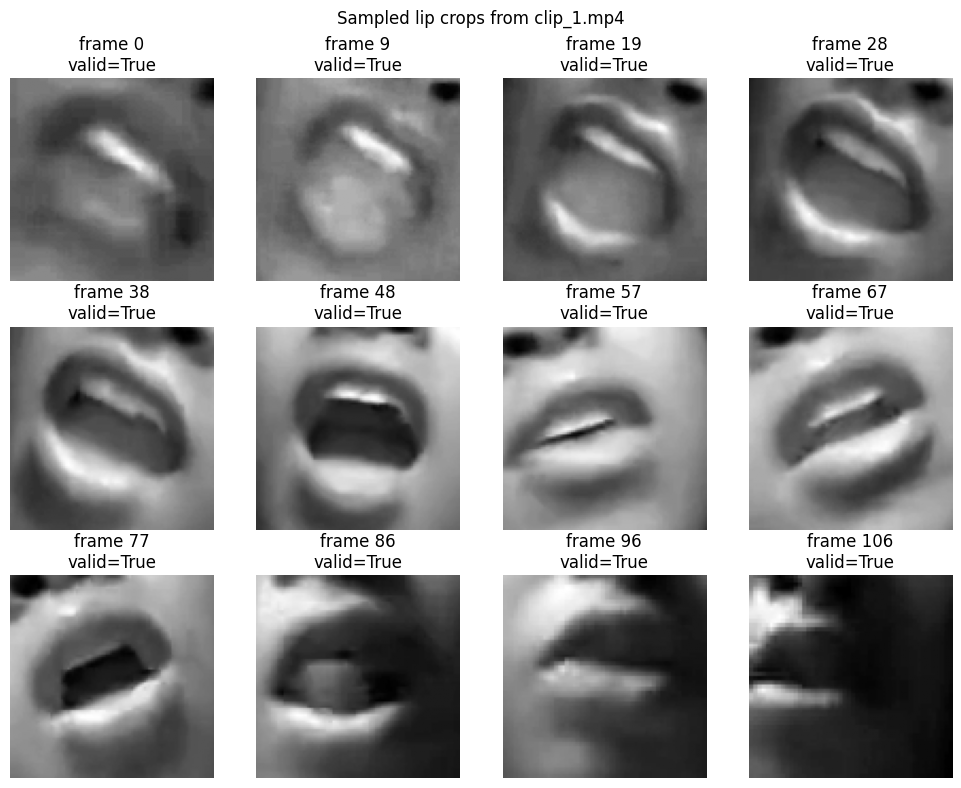

In [17]:
import matplotlib.pyplot as plt
import numpy as np

# Select up to 12 evenly spaced frames
num_samples = min(12, len(result.crops))
sample_positions = np.linspace(
    0,
    len(result.crops) - 1,
    num_samples,
    dtype=int,
)

fig, axes = plt.subplots(3, 4, figsize=(10, 8))
axes = axes.ravel()

for ax, position in zip(axes, sample_positions):
    ax.imshow(result.crops[position], cmap="gray")
    ax.set_title(
        f"frame {result.frame_indices[position]}\n"
        f"valid={result.valid[position]}"
    )
    ax.axis("off")

# Hide unused axes if the clip has fewer than 12 frames
for ax in axes[num_samples:]:
    ax.axis("off")

plt.suptitle("Sampled lip crops from clip_1.mp4")
plt.tight_layout()
plt.show()


In [18]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

from lipscribe.crop import crop_video

# Find the five clips in Drive
CLIPS_DIR = PROJECT_ROOT / "data" / "clips"
clips = sorted(CLIPS_DIR.glob("*.mp4"))

assert len(clips) == 5, f"Expected 5 clips, found {len(clips)}"

all_results = {}

for clip_path in clips:
    print(f"Processing {clip_path.name}...")

    clip_result = crop_video(
        video_path=clip_path,
        model_path=FACE_LANDMARKER_MODEL,
    )

    all_results[clip_path.name] = clip_result

    print(
        f"  frames={len(clip_result.crops)}, "
        f"valid={int(clip_result.valid.sum())}/{len(clip_result.valid)}, "
        f"shape={clip_result.crops.shape}, "
        f"dtype={clip_result.crops.dtype}"
    )

print("\nAll five clips processed successfully.")


Processing clip_1.mp4...
  frames=107, valid=107/107, shape=(107, 96, 96), dtype=uint8
Processing clip_2.mp4...
  frames=75, valid=75/75, shape=(75, 96, 96), dtype=uint8
Processing clip_3.mp4...
  frames=207, valid=207/207, shape=(207, 96, 96), dtype=uint8
Processing clip_4.mp4...
  frames=97, valid=97/97, shape=(97, 96, 96), dtype=uint8
Processing clip_5.mp4...
  frames=53, valid=53/53, shape=(53, 96, 96), dtype=uint8

All five clips processed successfully.


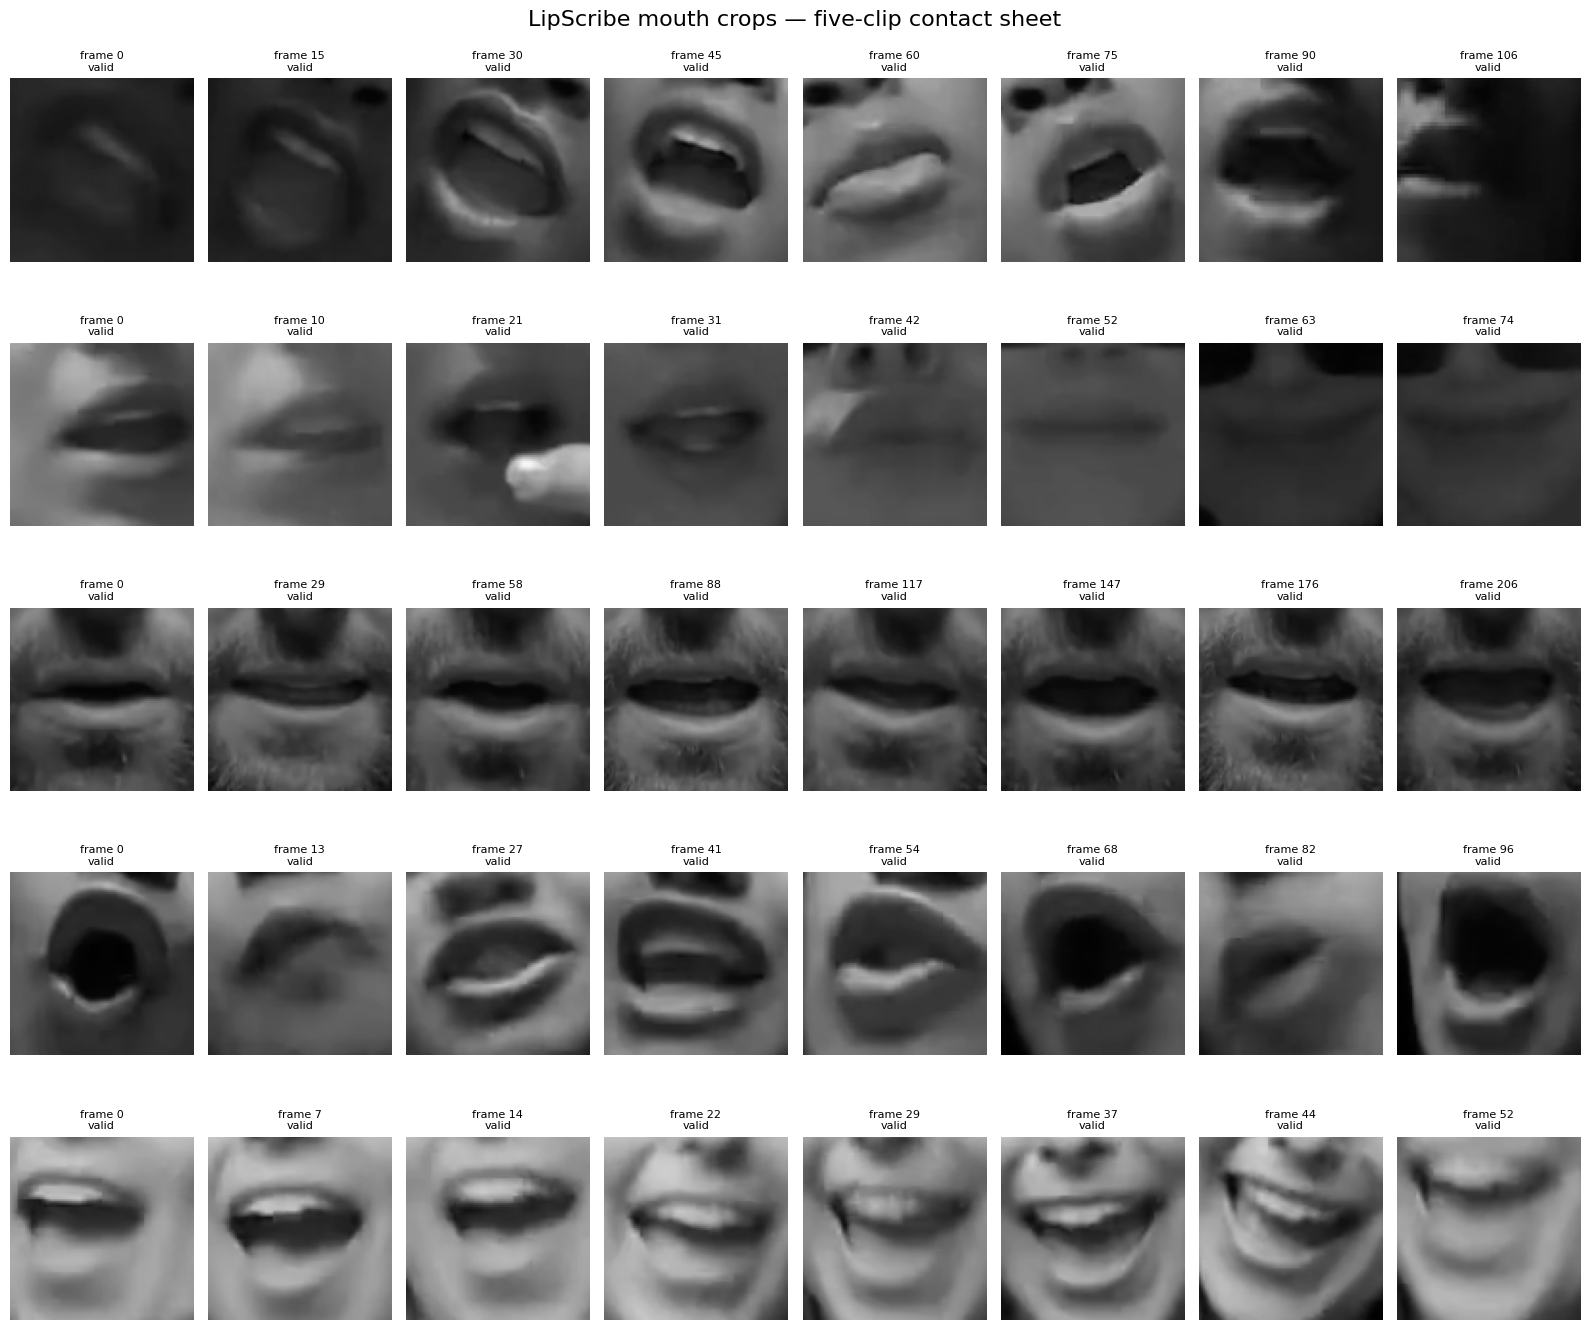

Contact sheet saved to:
/content/drive/MyDrive/LipScribe/artifacts/contact_sheets/lip_crops_all_clips_v001.png


In [19]:
CONTACT_SHEET_PATH = (
    PROJECT_ROOT
    / "artifacts"
    / "contact_sheets"
    / "lip_crops_all_clips_v001.png"
)

columns = 8
rows = len(clips)

fig, axes = plt.subplots(
    rows,
    columns,
    figsize=(16, 2.8 * rows),
    squeeze=False,
)

for row_index, clip_path in enumerate(clips):
    clip_result = all_results[clip_path.name]
    n_frames = len(clip_result.crops)

    sample_positions = np.linspace(
        0,
        n_frames - 1,
        columns,
        dtype=int,
    )

    for column_index, position in enumerate(sample_positions):
        ax = axes[row_index, column_index]

        ax.imshow(
            clip_result.crops[position],
            cmap="gray",
            vmin=0,
            vmax=255,
        )

        is_valid = bool(clip_result.valid[position])
        status = "valid" if is_valid else "interpolated"

        ax.set_title(
            f"frame {clip_result.frame_indices[position]}\n{status}",
            fontsize=8,
        )
        ax.axis("off")

    # Add clip name on the left side of each row
    axes[row_index, 0].set_ylabel(
        clip_path.name,
        fontsize=10,
        rotation=90,
        labelpad=20,
    )

fig.suptitle(
    "LipScribe mouth crops — five-clip contact sheet",
    fontsize=16,
)

plt.tight_layout()

CONTACT_SHEET_PATH.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(
    CONTACT_SHEET_PATH,
    dpi=180,
    bbox_inches="tight",
)

plt.show()

print("Contact sheet saved to:")
print(CONTACT_SHEET_PATH)


In [20]:
%%writefile /content/drive/MyDrive/LipScribe/tests/test_crop.py

from pathlib import Path

import cv2
import numpy as np

from lipscribe.crop import (
    OUTPUT_SIZE,
    centred_moving_average,
    crop_with_edge_padding,
    get_lip_indices,
)


def test_lip_indices_are_loaded_from_mediapipe_connections():
    indices = get_lip_indices()

    assert isinstance(indices, np.ndarray)
    assert indices.dtype == np.int32
    assert len(indices) > 0


def test_centered_moving_average_preserves_shape():
    values = np.array(
        [
            [0.0, 10.0, 20.0],
            [2.0, 12.0, 22.0],
            [4.0, 14.0, 24.0],
            [6.0, 16.0, 26.0],
            [8.0, 18.0, 28.0],
        ],
        dtype=np.float32,
    )

    smoothed = centred_moving_average(values, radius=2)

    assert smoothed.shape == values.shape
    assert np.isfinite(smoothed).all()


def test_edge_padded_crop_shape_and_dtype():
    frame_rgb = np.zeros(
        (40, 60, 3),
        dtype=np.uint8,
    )

    crop = crop_with_edge_padding(
        frame_rgb,
        center_x=2,
        center_y=3,
        side=30,
    )

    assert crop.shape == OUTPUT_SIZE
    assert crop.dtype == np.uint8


def test_crop_output_for_all_five_clips():
    clips_dir = Path("/content/drive/MyDrive/LipScribe/data/clips")
    model_path = Path(
        "/content/drive/MyDrive/LipScribe/models/face_landmarker.task"
    )

    clips = sorted(clips_dir.glob("*.mp4"))

    assert len(clips) == 5, (
        f"Expected 5 clips, found {len(clips)}"
    )

    # Import here so the simple unit tests above do not need to initialize
    # Face Landmarker unless this integration test is being run.
    from lipscribe.crop import crop_video

    for clip_path in clips:
        result = crop_video(
            video_path=clip_path,
            model_path=model_path,
        )

        assert result.crops.ndim == 3
        assert result.crops.shape[1:] == (96, 96)
        assert result.crops.dtype == np.uint8

        assert result.valid.ndim == 1
        assert result.valid.dtype == np.bool_
        assert len(result.valid) == len(result.crops)

        assert result.frame_indices.ndim == 1
        assert len(result.frame_indices) == len(result.crops)

        expected_indices = np.arange(
            len(result.crops),
            dtype=np.int64,
        )

        np.testing.assert_array_equal(
            result.frame_indices,
            expected_indices,
        )


Overwriting /content/drive/MyDrive/LipScribe/tests/test_crop.py


In [21]:
%%writefile /content/drive/MyDrive/LipScribe/src/lipscribe/__init__.py

"""LipScribe preprocessing and model components."""


Overwriting /content/drive/MyDrive/LipScribe/src/lipscribe/__init__.py


In [22]:
!PYTHONPATH=/content/drive/MyDrive/LipScribe/src pytest -q tests/test_crop.py



....                                                                     [100%]
4 passed in 16.03s


In [23]:
from pathlib import Path
import json
import numpy as np

from lipscribe.crop import crop_video

CROPS_DIR = PROJECT_ROOT / "artifacts" / "crops"
METADATA_DIR = PROJECT_ROOT / "artifacts" / "results"

CROPS_DIR.mkdir(parents=True, exist_ok=True)
METADATA_DIR.mkdir(parents=True, exist_ok=True)

crop_summary = {}

for clip_path in clips:
    print(f"Saving crops for {clip_path.name}...")

    result = crop_video(
        video_path=clip_path,
        model_path=FACE_LANDMARKER_MODEL,
    )

    clip_name = clip_path.stem

    crops_path = CROPS_DIR / f"{clip_name}_crops.npy"
    valid_path = CROPS_DIR / f"{clip_name}_valid.npy"
    indices_path = CROPS_DIR / f"{clip_name}_frame_indices.npy"

    np.save(crops_path, result.crops)
    np.save(valid_path, result.valid)
    np.save(indices_path, result.frame_indices)

    crop_summary[clip_name] = {
        "video": str(clip_path),
        "num_frames": int(len(result.crops)),
        "valid_frames": int(result.valid.sum()),
        "invalid_frames": int((~result.valid).sum()),
        "crop_shape": list(result.crops.shape),
        "crop_dtype": str(result.crops.dtype),
        "crops_file": str(crops_path),
        "valid_file": str(valid_path),
        "frame_indices_file": str(indices_path),
    }

summary_path = METADATA_DIR / "crop_summary_v001.json"

with summary_path.open("w", encoding="utf-8") as file:
    json.dump(crop_summary, file, indent=2)

print("\nSaved crop arrays and metadata.")
print("Summary:", summary_path)


Saving crops for clip_1.mp4...
Saving crops for clip_2.mp4...
Saving crops for clip_3.mp4...
Saving crops for clip_4.mp4...
Saving crops for clip_5.mp4...

Saved crop arrays and metadata.
Summary: /content/drive/MyDrive/LipScribe/artifacts/results/crop_summary_v001.json
